<a href="https://colab.research.google.com/github/ahmadmukhtasor-0309-lgtm/Tugas-Machine-Learning/blob/main/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [2]:

kaggle_filename = (
    'data.csv' if os.path.exists('data.csv')
    else 'breast-cancer.csv'
    if os.path.exists('breast-cancer.csv')
    else None
)

if kaggle_filename:
    print(f"[*] Memuat dataset Kaggle dari: {kaggle_filename}")
    df = pd.read_csv(kaggle_filename)

    cols_to_drop = [
        c for c in ['id', 'Unnamed: 32']
        if c in df.columns
    ]
    df = df.drop(columns=cols_to_drop)

    if 'diagnosis' in df.columns:
        y = df['diagnosis'].map({'M': 0, 'B': 1}).values
        X = df.drop(columns=['diagnosis'])
    else:
        target_col = df.columns[-1]
        y = df[target_col].values
        X = df.drop(columns=[target_col])

    feature_names = list(X.columns)
    target_names = ['malignant', 'benign']

else:
    print(
        "[*] File CSV Kaggle tidak ditemukan. "
        "Menggunakan dataset bawaan Scikit-Learn..."
    )

    data = load_breast_cancer(as_frame=True)
    X = data.data
    y = data.target.values
    feature_names = list(data.feature_names)
    target_names = list(data.target_names)

print("Ukuran data:", X.shape)
print("Distribusi kelas:", np.bincount(y))

[*] File CSV Kaggle tidak ditemukan. Menggunakan dataset bawaan Scikit-Learn...
Ukuran data: (569, 30)
Distribusi kelas: [212 357]


In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(
    f"Data latih: {X_train.shape[0]} sampel | "
    f"Data uji: {X_test.shape[0]} sampel"
)

Data latih: 455 sampel | Data uji: 114 sampel


In [4]:

tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train, y_train)

print("Model Decision Tree tanpa pruning berhasil dilatih.")

Model Decision Tree tanpa pruning berhasil dilatih.


In [5]:

tree_pruned = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

tree_pruned.fit(X_train, y_train)

print("Model pre-pruning berhasil dilatih.")

Model pre-pruning berhasil dilatih.


In [6]:

path = tree_full.cost_complexity_pruning_path(
    X_train, y_train
)

ccp_alpha_terpilih = path.ccp_alphas[
    len(path.ccp_alphas) // 2
]

tree_ccp = DecisionTreeClassifier(
    ccp_alpha=ccp_alpha_terpilih,
    random_state=42
)

tree_ccp.fit(X_train, y_train)

print("Model post-pruning berhasil dilatih.")
print("ccp_alpha contoh:", ccp_alpha_terpilih)

Model post-pruning berhasil dilatih.
ccp_alpha contoh: 0.005274725274725275


In [7]:

print("=" * 65)
print("EVALUASI PERFORMA MODEL (Praktikum 5.5)")
print("=" * 65)

models = [
    ("Tanpa Pruning", tree_full),
    ("Pre-Pruning", tree_pruned),
    ("Post-Pruning (CCP)", tree_ccp)
]

for nama, model in models:
    acc_train = accuracy_score(
        y_train, model.predict(X_train)
    )

    acc_test = accuracy_score(
        y_test, model.predict(X_test)
    )

    gap = acc_train - acc_test

    print(
        f"{nama:18}: "
        f"Akurasi Train={acc_train:.3f}, "
        f"Akurasi Test={acc_test:.3f}, "
        f"Gap={gap:.3f}"
    )

EVALUASI PERFORMA MODEL (Praktikum 5.5)
Tanpa Pruning     : Akurasi Train=1.000, Akurasi Test=0.912, Gap=0.088
Pre-Pruning       : Akurasi Train=0.976, Akurasi Test=0.921, Gap=0.055
Post-Pruning (CCP): Akurasi Train=0.978, Akurasi Test=0.930, Gap=0.048


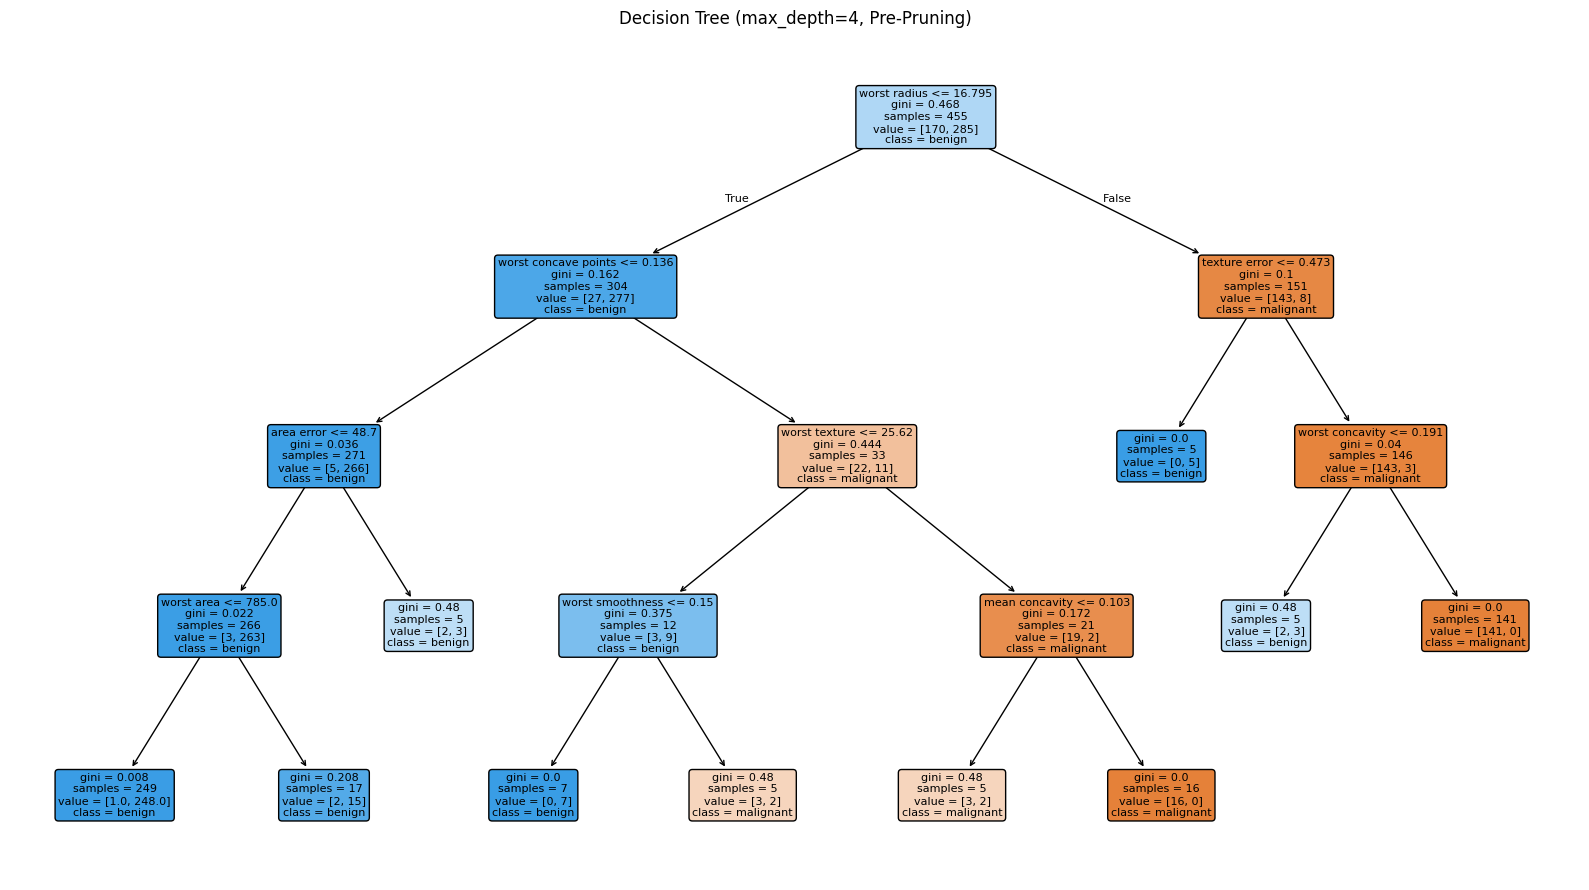

In [8]:

plt.figure(figsize=(16, 9))

plot_tree(
    tree_pruned,
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree (max_depth=4, Pre-Pruning)")
plt.tight_layout()
plt.show()

In [9]:

print("\n" + "=" * 65)
print("LATIHAN 1: EKSPERIMEN PARAMETER PRE-PRUNING")
print("=" * 65)

best_pre_acc = 0.0
best_params = {}

for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=42
        )

        model.fit(X_train, y_train)

        acc = accuracy_score(
            y_test, model.predict(X_test)
        )

        print(
            f"max_depth={str(depth):4}, "
            f"min_samples_leaf={min_leaf:2}: "
            f"akurasi test={acc:.3f}"
        )

        if acc > best_pre_acc:
            best_pre_acc = acc
            best_params = {
                'max_depth': depth,
                'min_samples_leaf': min_leaf
            }

print("\nKombinasi Pre-Pruning Terbaik:", best_params)
print(f"Akurasi Test Terbaik: {best_pre_acc:.3f}")


LATIHAN 1: EKSPERIMEN PARAMETER PRE-PRUNING
max_depth=2   , min_samples_leaf= 1: akurasi test=0.895
max_depth=2   , min_samples_leaf= 5: akurasi test=0.895
max_depth=2   , min_samples_leaf=10: akurasi test=0.904
max_depth=4   , min_samples_leaf= 1: akurasi test=0.939
max_depth=4   , min_samples_leaf= 5: akurasi test=0.921
max_depth=4   , min_samples_leaf=10: akurasi test=0.947
max_depth=6   , min_samples_leaf= 1: akurasi test=0.912
max_depth=6   , min_samples_leaf= 5: akurasi test=0.930
max_depth=6   , min_samples_leaf=10: akurasi test=0.947
max_depth=None, min_samples_leaf= 1: akurasi test=0.912
max_depth=None, min_samples_leaf= 5: akurasi test=0.930
max_depth=None, min_samples_leaf=10: akurasi test=0.947

Kombinasi Pre-Pruning Terbaik: {'max_depth': 4, 'min_samples_leaf': 10}
Akurasi Test Terbaik: 0.947


In [10]:

path = tree_full.cost_complexity_pruning_path(
    X_train, y_train
)

ccp_alphas = path.ccp_alphas
impurities = path.impurities

print("Jumlah kandidat ccp_alpha:", len(ccp_alphas))
print("Daftar ccp_alpha:")
print(ccp_alphas)

Jumlah kandidat ccp_alpha: 14
Daftar ccp_alpha:
[0.         0.00218083 0.0028662  0.0029304  0.00395604 0.00425059
 0.00502355 0.00527473 0.00593407 0.00764113 0.01439037 0.02038595
 0.05433359 0.32661707]


In [11]:

akurasi_test = []
tree_models = []

for alpha in ccp_alphas:
    m = DecisionTreeClassifier(
        ccp_alpha=alpha,
        random_state=42
    )

    m.fit(X_train, y_train)

    akurasi_test.append(
        accuracy_score(y_test, m.predict(X_test))
    )

    tree_models.append(m)

print("Pengujian seluruh kandidat alpha selesai.")
print("Jumlah model yang diuji:", len(tree_models))

Pengujian seluruh kandidat alpha selesai.
Jumlah model yang diuji: 14


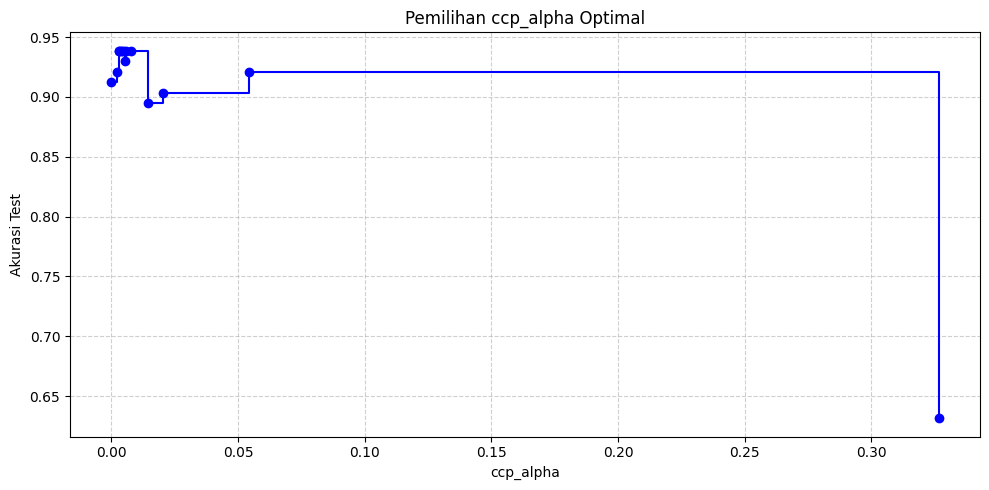

In [12]:

plt.figure(figsize=(10, 5))

plt.plot(
    ccp_alphas,
    akurasi_test,
    marker='o',
    drawstyle="steps-post",
    color='b'
)

plt.xlabel("ccp_alpha")
plt.ylabel("Akurasi Test")
plt.title("Pemilihan ccp_alpha Optimal")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [13]:

best_idx = int(np.argmax(akurasi_test))

best_ccp_alpha = ccp_alphas[best_idx]
best_test_acc = akurasi_test[best_idx]
best_tree = tree_models[best_idx]

print("\n--- HASIL PENENTUAN CCP_ALPHA OPTIMAL ---")
print(f"ccp_alpha optimal: {best_ccp_alpha:.6f}")
print(f"Akurasi test tertinggi: {best_test_acc:.3f}")

print(
    f"Jumlah leaf node Tree Full: "
    f"{tree_full.get_n_leaves()} leaves "
    f"(Kedalaman: {tree_full.get_depth()})"
)

print(
    f"Jumlah leaf node Tree Optimal: "
    f"{best_tree.get_n_leaves()} leaves "
    f"(Kedalaman: {best_tree.get_depth()})"
)


--- HASIL PENENTUAN CCP_ALPHA OPTIMAL ---
ccp_alpha optimal: 0.002866
Akurasi test tertinggi: 0.939
Jumlah leaf node Tree Full: 19 leaves (Kedalaman: 7)
Jumlah leaf node Tree Optimal: 12 leaves (Kedalaman: 5)


In [14]:

y_pred_opt = best_tree.predict(X_test)

print("\nLaporan Klasifikasi Model Optimal:")

print(
    classification_report(
        y_test,
        y_pred_opt,
        target_names=target_names
    )
)


Laporan Klasifikasi Model Optimal:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

